# 12-hour mean heat flux VS 12-hour mean W * 12-hour mean T

In [2]:
#  I will plot the following snapshots to compare the difference between the different average method
# 12-hour mean total heat flux & 12-hour mean W * 12-hour mean T
# spatial average 12-hour mean total heat flux & spatial average 12-hour mean W * 12-hour mean T
# submeso
import h5netcdf
import xarray as xr

path_scratch = '/scratch/jczhang/'
path_data = 'data_5km/save_coarse/'
sub = "13901616_nc/wT_sub_12h_blocks_true.nc"
meso = "13901616_nc/wT_meso_12h_blocks_true.nc"
total = "13901616_nc/wT_bar_12h_blocks_true.nc"
sub_o = "13901616_nc/wT_sub_12h_blocks.nc"
meso_o = "13901616_nc/wT_meso_12h_blocks.nc"
total_o = "13901616_nc/wT_bar_12h_blocks.nc"

submeso_heat_flux = xr.open_dataset(path_scratch + path_data + sub, engine="h5netcdf")
meso_heat_flux = xr.open_dataset(path_scratch + path_data + meso, engine="h5netcdf")
total_heat_flux = xr.open_dataset(path_scratch + path_data + total, engine="h5netcdf")
submeso_heat_flux_o = xr.open_dataset(path_scratch + path_data + sub_o, engine="h5netcdf")
meso_heat_flux_o = xr.open_dataset(path_scratch + path_data + meso_o, engine="h5netcdf")
total_heat_flux_o = xr.open_dataset(path_scratch + path_data + total_o, engine="h5netcdf")

In [7]:
print(submeso_heat_flux)

<xarray.Dataset> Size: 969MB
Dimensions:    (time: 687, k: 49, j: 120, i: 60)
Coordinates:
  * time       (time) int64 5kB 22719600 22721328 22723056 ... 23903280 23905008
Dimensions without coordinates: k, j, i
Data variables:
    wT_sub_kC  (time, k, j, i) float32 969MB ...
Attributes:
    origin_iter:            22719600
    hourly_step:            144
    block_size:             12
    time_is_block_start:    1
    box_j:                  10
    box_i:                  10
    variable:               wT_sub_kC
    to_wm2:                 1
    total_flux_definition:  mean(W,12h) * interp_Zleft(mean(T,12h))


In [5]:
print(total_heat_flux)

<xarray.Dataset> Size: 1GB
Dimensions:    (time: 803, k: 49, j: 120, i: 60)
Coordinates:
  * time       (time) int64 6kB 22719600 22721328 22723056 ... 24103728 24105456
Dimensions without coordinates: k, j, i
Data variables:
    wT_bar_kC  (time, k, j, i) float32 1GB ...
Attributes:
    origin_iter:            22719600
    hourly_step:            144
    block_size:             12
    time_is_block_start:    1
    box_j:                  10
    box_i:                  10
    variable:               wT_bar_kC
    to_wm2:                 1
    total_flux_definition:  mean(W,12h) * interp_Zleft(mean(T,12h))


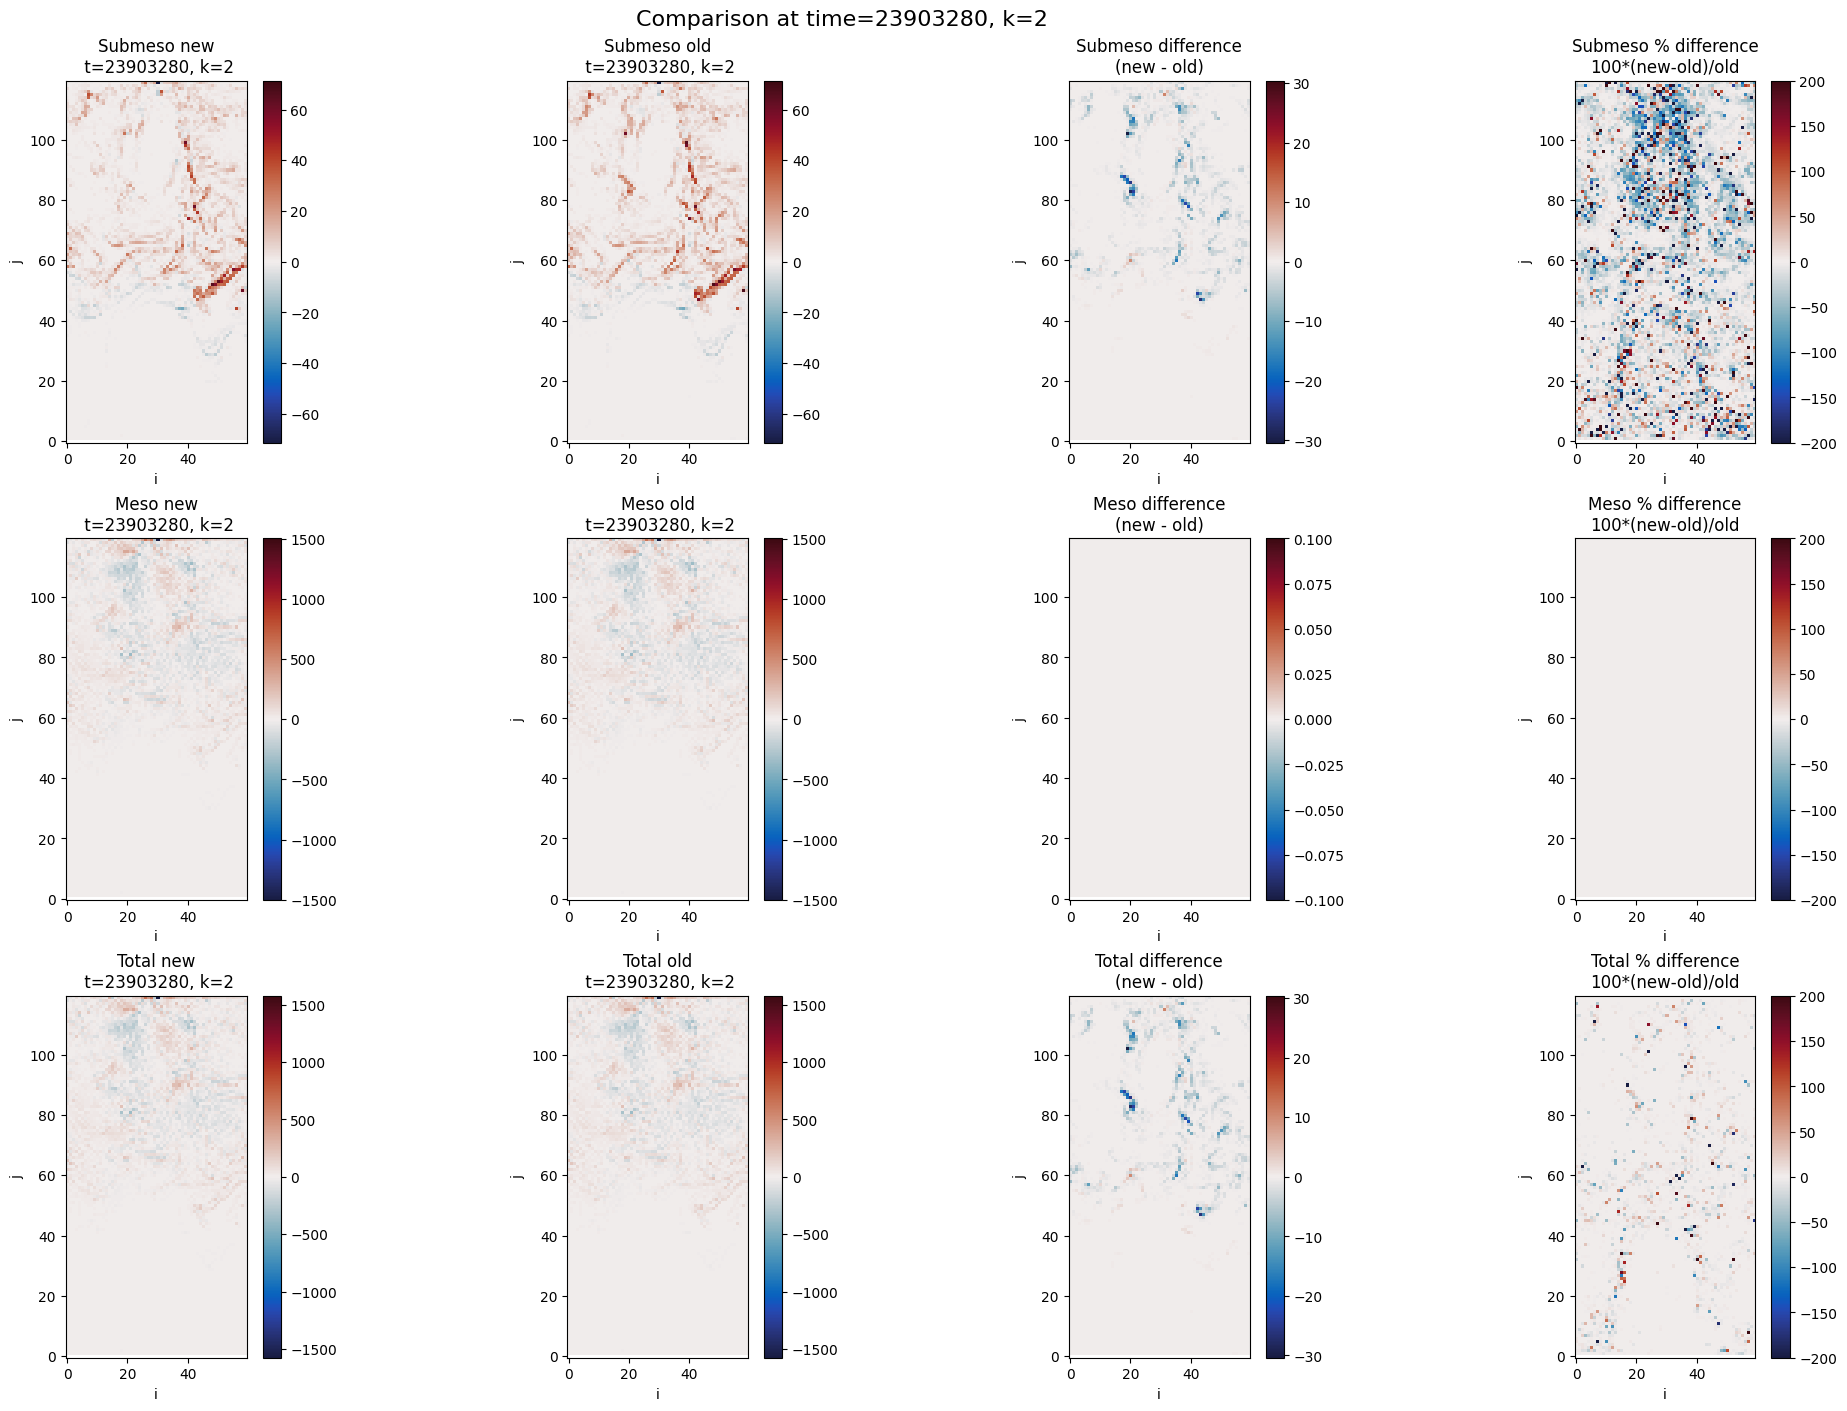

In [11]:
import numpy as np
import xarray as xr
import matplotlib.pyplot as plt
import cmocean

# -----------------------------
# choose one real time point and one vertical level
# -----------------------------
t_val = 23903280
k_idx = 2

# -----------------------------
# variable names
# -----------------------------
sub_var = "wT_sub_kC"
meso_var = "wT_meso_kC"
total_var = "wT_bar_kC"

# -----------------------------
# helper functions
# -----------------------------
def get_2d_slice(ds, varname, t_val, k_idx=2):
    da = ds[varname].sel(time=t_val).isel(k=k_idx)
    return da

def compute_diff_and_pct(new_da, old_da, eps=1e-12):
    diff = new_da - old_da
    pct = 100.0 * diff / xr.where(np.abs(old_da) > eps, old_da, np.nan)
    return diff, pct

def sym_vlim(da):
    vmax = np.nanmax(np.abs(da.values))
    return -vmax, vmax

def common_vlim(a, b):
    vmax = np.nanmax([np.nanmax(np.abs(a.values)), np.nanmax(np.abs(b.values))])
    return -vmax, vmax

# -----------------------------
# extract slices at real time
# -----------------------------
sub_new = get_2d_slice(submeso_heat_flux, sub_var, t_val, k_idx)
sub_old = get_2d_slice(submeso_heat_flux_o, sub_var, t_val, k_idx)

meso_new = get_2d_slice(meso_heat_flux, meso_var, t_val, k_idx)
meso_old = get_2d_slice(meso_heat_flux_o, meso_var, t_val, k_idx)

total_new = get_2d_slice(total_heat_flux, total_var, t_val, k_idx)
total_old = get_2d_slice(total_heat_flux_o, total_var, t_val, k_idx)

# -----------------------------
# differences
# -----------------------------
sub_diff, sub_pct = compute_diff_and_pct(sub_new, sub_old)
meso_diff, meso_pct = compute_diff_and_pct(meso_new, meso_old)
total_diff, total_pct = compute_diff_and_pct(total_new, total_old)

# -----------------------------
# symmetric color limits for all panels
# -----------------------------
sub_vmin, sub_vmax = common_vlim(sub_new, sub_old)
meso_vmin, meso_vmax = common_vlim(meso_new, meso_old)
total_vmin, total_vmax = common_vlim(total_new, total_old)

sub_dvmin, sub_dvmax = sym_vlim(sub_diff)
meso_dvmin, meso_dvmax = sym_vlim(meso_diff)
total_dvmin, total_dvmax = sym_vlim(total_diff)

sub_pvmin, sub_pvmax = sym_vlim(sub_pct)
meso_pvmin, meso_pvmax = sym_vlim(meso_pct)
total_pvmin, total_pvmax = sym_vlim(total_pct)

# -----------------------------
# plot
# -----------------------------
fig, axes = plt.subplots(3, 4, figsize=(20, 14), constrained_layout=True)

rows = [
    ("Submeso", sub_new, sub_old, sub_diff, sub_pct,
     sub_vmin, sub_vmax, sub_dvmin, sub_dvmax, sub_pvmin, sub_pvmax),
    ("Meso", meso_new, meso_old, meso_diff, meso_pct,
     meso_vmin, meso_vmax, meso_dvmin, meso_dvmax, meso_pvmin, meso_pvmax),
    ("Total", total_new, total_old, total_diff, total_pct,
     total_vmin, total_vmax, total_dvmin, total_dvmax, total_pvmin, total_pvmax),
]

for r, (label, new_da, old_da, diff_da, pct_da,
        vmin, vmax, dvmin, dvmax, pvmin, pvmax) in enumerate(rows):

    im0 = axes[r, 0].imshow(
        new_da.values, origin="lower",
        cmap=cmocean.cm.balance, vmin=vmin, vmax=vmax
    )
    axes[r, 0].set_title(f"{label} new\n t={t_val}, k={k_idx}")
    plt.colorbar(im0, ax=axes[r, 0], fraction=0.046, pad=0.04)

    im1 = axes[r, 1].imshow(
        old_da.values, origin="lower",
        cmap=cmocean.cm.balance, vmin=vmin, vmax=vmax
    )
    axes[r, 1].set_title(f"{label} old\n t={t_val}, k={k_idx}")
    plt.colorbar(im1, ax=axes[r, 1], fraction=0.046, pad=0.04)

    im2 = axes[r, 2].imshow(
        diff_da.values, origin="lower",
        cmap=cmocean.cm.balance, vmin=dvmin, vmax=dvmax
    )
    axes[r, 2].set_title(f"{label} difference\n(new - old)")
    plt.colorbar(im2, ax=axes[r, 2], fraction=0.046, pad=0.04)

    im3 = axes[r, 3].imshow(
        pct_da.values, origin="lower",
        cmap=cmocean.cm.balance, vmin=-200, vmax=200
    )
    axes[r, 3].set_title(f"{label} % difference\n100*(new-old)/old")
    plt.colorbar(im3, ax=axes[r, 3], fraction=0.046, pad=0.04)

    for c in range(4):
        axes[r, c].set_xlabel("i")
        axes[r, c].set_ylabel("j")

plt.suptitle(f"Comparison at time={t_val}, k={k_idx}", fontsize=16)
plt.show()